In [1]:

import pandas as pd

# Load the dataset
df = pd.read_csv("hour.csv")

# Display the first 5 rows
df.head()


,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


In [2]:

# Check the dataset size
print("Dataset Shape:", df.shape)

# Check column information
print("\nDataset Information:")
df.info()

# Check missing values
print("\nMissing Values:")
print(df.isnull().sum())

# Display statistical summary
df.describe()


Dataset Shape: (17379, 17)

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 17379 entries, 0 to 17378
Data columns (total 17 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     17379 non-null  int64  
 1   dteday      17379 non-null  str    
 2   season      17379 non-null  int64  
 3   yr          17379 non-null  int64  
 4   mnth        17379 non-null  int64  
 5   hr          17379 non-null  int64  
 6   holiday     17379 non-null  int64  
 7   weekday     17379 non-null  int64  
 8   workingday  17379 non-null  int64  
 9   weathersit  17379 non-null  int64  
 10  temp        17379 non-null  float64
 11  atemp       17379 non-null  float64
 12  hum         17379 non-null  float64
 13  windspeed   17379 non-null  float64
 14  casual      17379 non-null  int64  
 15  registered  17379 non-null  int64  
 16  cnt         17379 non-null  int64  
dtypes: float64(4), int64(12), str(1)
memory usage: 2.4 MB

Missing Values

,instant,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
count,17379.0000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000
mean,8690.0000,2.501640,0.502561,6.537775,11.546752,0.028770,3.003683,0.682721,1.425283,0.496987,0.475775,0.627229,0.190098,35.676218,153.786869,189.463088
std,5017.0295,1.106918,0.500008,3.438776,6.914405,0.167165,2.005771,0.465431,0.639357,0.192556,0.171850,0.192930,0.122340,49.305030,151.357286,181.387599
min,1.0000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.020000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000
25%,4345.5000,2.000000,0.000000,4.000000,6.000000,0.000000,1.000000,0.000000,1.000000,0.340000,0.333300,0.480000,0.104500,4.000000,34.000000,40.000000
50%,8690.0000,3.000000,1.000000,7.000000,12.000000,0.000000,3.000000,1.000000,1.000000,0.500000,0.484800,0.630000,0.194000,17.000000,115.000000,142.000000
75%,13034.5000,3.000000,1.000000,10.000000,18.000000,0.000000,5.000000,1.000000,2.000000,0.660000,0.621200,0.780000,0.253700,48.000000,220.000000,281.000000
max,17379.0000,4.000000,1.000000,12.000000,23.000000,1.000000,6.000000,1.000000,4.000000,1.000000,1.000000,1.000000,0.850700,367.000000,886.000000,977.000000


In [3]:

# Remove columns that are not needed
df_clean = df.drop(columns=[
    'instant',
    'dteday',
    'casual',
    'registered'
])

# Separate input features and target
X = df_clean.drop('cnt', axis=1)
y = df_clean['cnt']

# Display results
print("Input Features:", X.shape)
print("Target:", y.shape)
print("\nFeature Names:")
print(X.columns.tolist())


Input Features: (17379, 12)
Target: (17379,)

Feature Names:
['season', 'yr', 'mnth', 'hr', 'holiday', 'weekday', 'workingday', 'weathersit', 'temp', 'atemp', 'hum', 'windspeed']


In [4]:

from sklearn.model_selection import KFold
from sklearn.preprocessing import StandardScaler

# Create 10-fold cross-validation
kf = KFold(n_splits=10, shuffle=True, random_state=42)

# Check the number of folds
print("Number of folds:", kf.get_n_splits(X))

print("Total records:", len(X))


Number of folds: 10
Total records: 17379


In [5]:

# Import five machine learning algorithms
from sklearn.linear_model import Ridge, Lasso
from sklearn.svm import SVR
from sklearn.ensemble import ExtraTreesRegressor, AdaBoostRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import cross_val_score

# Create five models
models = {
    "Ridge Regression": make_pipeline(StandardScaler(), Ridge()),
    "Lasso Regression": make_pipeline(StandardScaler(), Lasso()),
    "SVR": make_pipeline(StandardScaler(), SVR()),
    "Extra Trees": ExtraTreesRegressor(n_estimators=100, random_state=42),
    "AdaBoost": AdaBoostRegressor(n_estimators=100, random_state=42)
}

print("Five machine learning models are ready!")


Five machine learning models are ready!


In [6]:

import numpy as np
import pandas as pd
from sklearn.model_selection import cross_val_score

# Store the results
results = []

# Train and evaluate each model
for name, model in models.items():
    print("Training:", name)

    scores = cross_val_score(
        model,
        X,
        y,
        cv=kf,
        scoring="neg_root_mean_squared_error",
        n_jobs=-1
    )

    rmse = -scores

    results.append({
        "Model": name,
        "Mean RMSE": rmse.mean(),
        "Std RMSE": rmse.std()
    })

    print("Mean RMSE:", round(rmse.mean(), 2))
    print("--------------------------")

# Create comparison table
results_df = pd.DataFrame(results)
results_df = results_df.sort_values("Mean RMSE")

print("\nFinal Model Comparison:")
display(results_df)


Training: Ridge Regression
Mean RMSE: 141.83
--------------------------
Training: Lasso Regression
Mean RMSE: 141.85
--------------------------
Training: SVR
Mean RMSE: 140.33
--------------------------
Training: Extra Trees
Mean RMSE: 40.75
--------------------------
Training: AdaBoost
Mean RMSE: 106.51
--------------------------

Final Model Comparison:


,Model,Mean RMSE,Std RMSE
3,Extra Trees,40.751044,1.623871
4,AdaBoost,106.514301,2.754531
2,SVR,140.328078,4.694893
0,Ridge Regression,141.828790,3.903576
1,Lasso Regression,141.854254,3.913441


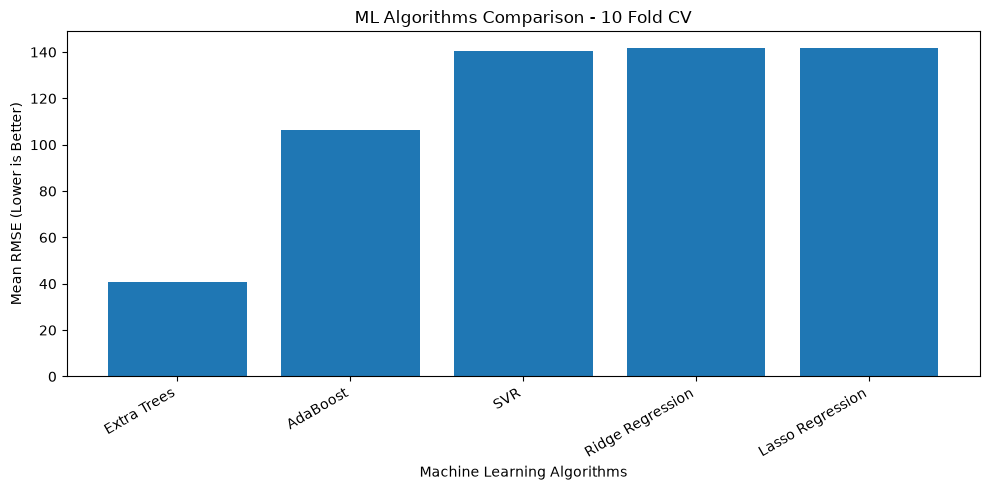

In [7]:

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.bar(results_df["Model"], results_df["Mean RMSE"])

plt.title("ML Algorithms Comparison - 10 Fold CV")
plt.xlabel("Machine Learning Algorithms")
plt.ylabel("Mean RMSE (Lower is Better)")

plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()


In [8]:

import joblib

# Select the best model
best_model = models["Extra Trees"]

# Train the model on the full dataset
best_model.fit(X, y)

# Save the trained model
joblib.dump(best_model, "bike_rental_model.pkl")

# Save the feature names for the web application
joblib.dump(X.columns.tolist(), "feature_names.pkl")

print("Best model trained successfully!")
print("Model saved as bike_rental_model.pkl")
print("Feature names saved as feature_names.pkl")


Best model trained successfully!
Model saved as bike_rental_model.pkl
Feature names saved as feature_names.pkl


In [9]:

%pip install streamlit


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2 -> 26.2.2
[notice] To update, run: C:\Users\User\AppData\Local\Programs\Python\Python313\python.exe -m pip install --upgrade pip


In [10]:

import streamlit as st

print("Streamlit installed successfully!")
print("Version:", st.__version__)


Streamlit installed successfully!
Version: 1.60.0
